In [1]:
!pip install umap-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import umap

In [3]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(
    X,
    columns=[
        'Sepal Length',
        'Sepal Width',
        'Petal Length',
        'Petal Width'
    ]
)

df['Species'] = y

In [4]:
print(df.head())
print(df.shape)

   Sepal Length  Sepal Width  Petal Length  Petal Width  Species
0           5.1          3.5           1.4          0.2        0
1           4.9          3.0           1.4          0.2        0
2           4.7          3.2           1.3          0.2        0
3           4.6          3.1           1.5          0.2        0
4           5.0          3.6           1.4          0.2        0
(150, 5)


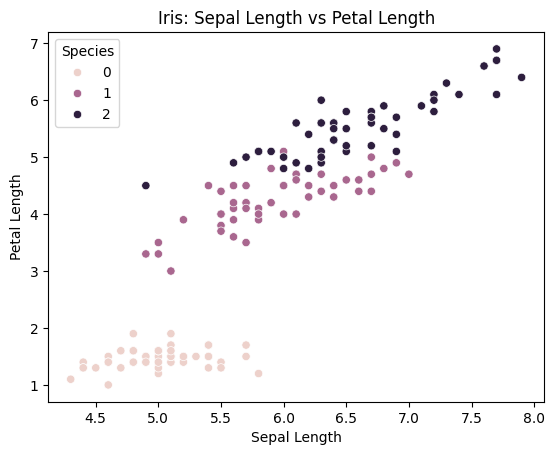

In [5]:
sns.scatterplot(
    data=df,
    x='Sepal Length',
    y='Petal Length',
    hue='Species'
)

plt.title("Iris: Sepal Length vs Petal Length")
plt.show()

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [7]:
pca = PCA(n_components=2)

pca_res = pca.fit_transform(X_scaled)

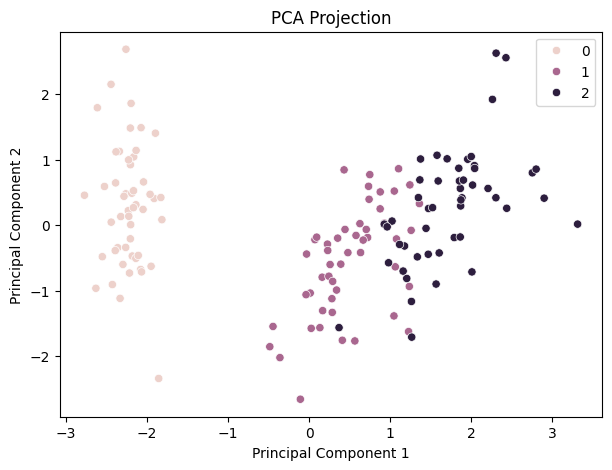

In [8]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    x=pca_res[:,0],
    y=pca_res[:,1],
    hue=y
)

plt.title("PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [9]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

tsne_res = tsne.fit_transform(X_scaled)

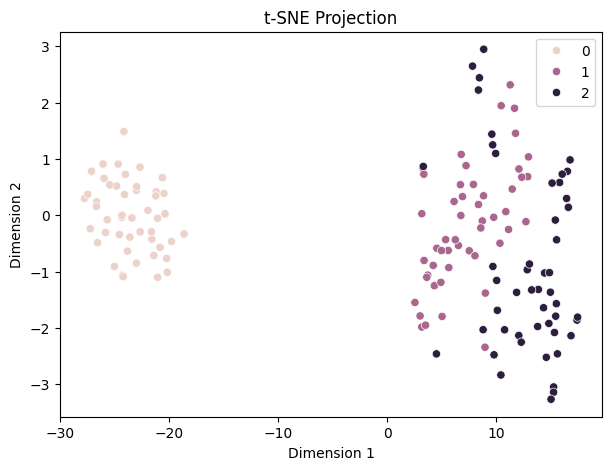

In [10]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    x=tsne_res[:,0],
    y=tsne_res[:,1],
    hue=y
)

plt.title("t-SNE Projection")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.show()

In [11]:
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    random_state=42
)

umap_res = umap_model.fit_transform(X_scaled)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


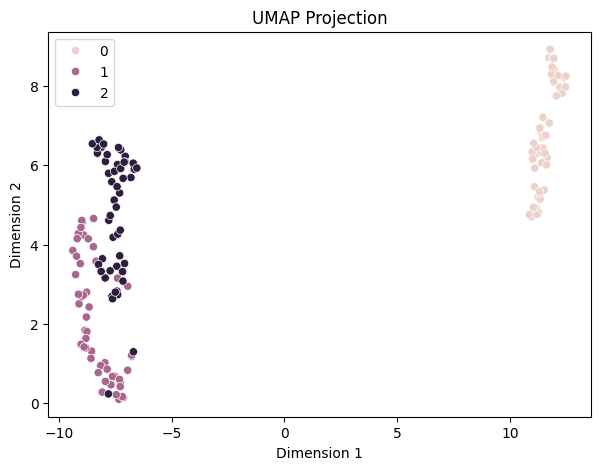

In [12]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    x=umap_res[:,0],
    y=umap_res[:,1],
    hue=y
)

plt.title("UMAP Projection")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.show()

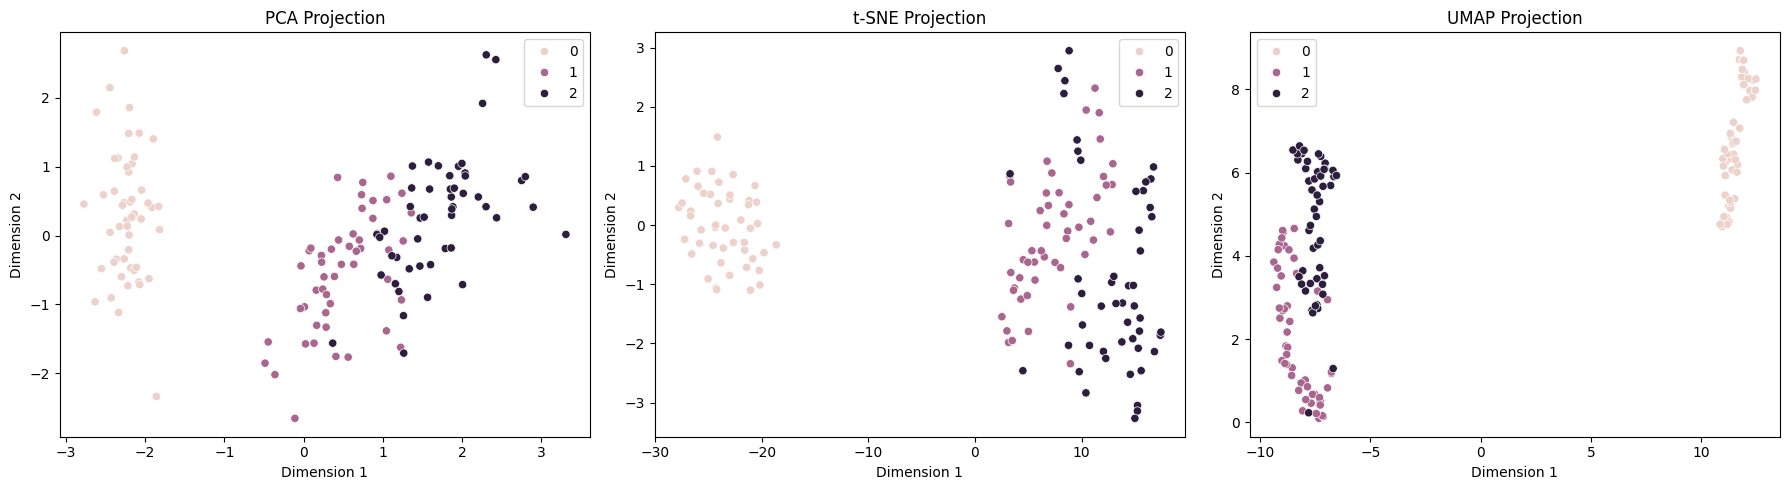

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

results = [
    ('PCA', pca_res),
    ('t-SNE', tsne_res),
    ('UMAP', umap_res)
]

for ax, (title, result) in zip(axes, results):

    sns.scatterplot(
        x=result[:, 0],
        y=result[:, 1],
        hue=y,
        ax=ax
    )

    ax.set_title(title + " Projection")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

plt.tight_layout()
plt.show()